# Lab02 — Scheduled transfer learning

Kết quả đọc từ run được chọn; không train lại khi thực thi notebook. Train học trọng số, validation chọn checkpoint, test đánh giá sau selection.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
sys.path.insert(0, str(Path.cwd()))
from src.utils import notebook_views as view
ROOT, RUN, OUT = view.context()
print("Run:", RUN.name)
display(pd.Series(json.loads((RUN / "config.json").read_text()), name="Config"))

Run: 20261030T092411Z_cifar10_scheduled64_6f6f0f4b


dataset                                                             CIFAR10
seed                                                                     42
split_seed                                                               42
threads                                                                   4
train_limit                                                               0
val_limit                                                                 0
test_limit                                                                0
models                                              [resnet18, densenet121]
learning_rates                                                      [0.001]
batch_sizes                                                           [128]
head_epochs                                                              12
finetune_epochs                                                          20
head_optimizer                                                        adamw
optimizer   

## 1. Kiến trúc và freeze

ResNet: layer4.1 + fc. DenseNet: block3 layer11–12,18–24; transition3; block4 layer1–4,13–16; norm5; classifier. Trainable <=50% mỗi model. BatchNorm running statistics cố định; weight/bias ở phần mở vẫn học. Dropout 0.2 bật khi train, tắt khi eval.

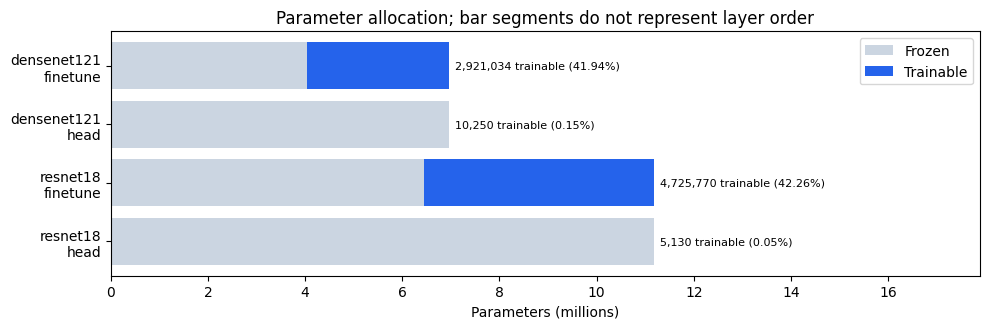

,model,stage,total,trainable,unfrozen_blocks
0,resnet18,head,11181642,5130,classifier
1,resnet18,finetune,11181642,4725770,layer4.1 + fc
2,densenet121,head,6964106,10250,classifier
3,densenet121,finetune,6964106,2921034,"block3:11–12,18–24 + transition3 + block4:1–4,..."


In [2]:
view.architecture_visual(RUN, OUT)

## 2. Lịch huấn luyện

Một recipe/model, batch 128 cố định; không grid search. Head 12 epoch, LR 1e-3. Fine-tune tối đa 20 epoch, backbone LR 1e-4 và head LR 1e-3. Cosine giảm từng nhóm còn 10%; LR cuối lịch đạt sau bước scheduler cuối. Early stopping loss: min_epochs=10, patience=7, min_delta=1e-4. Checkpoint chọn theo val accuracy, hòa xét loss.

Head dùng feature cache không augmentation; fine-tune train crop32/padding reflect4 và flip0.5 trước resize64/Normalize ImageNet. Validation/test không augmentation.

In [3]:
for name in pd.read_csv(RUN / "comparison.csv").model.unique():
    print(name)
    display(pd.read_csv(RUN / name / "search_results.csv"))
    display(pd.read_csv(RUN / name / "finetune_search_results.csv"))

resnet18


,trial,lr,batch_size,best_val_accuracy,best_val_loss,epochs_planned,epochs_completed,stop_reason,early_stopping,minimum_observed_val_loss,...,train_seconds,resumed,resume_boundary,timing_policy,train_pass_seconds,validation_seconds,train_images_per_second,peak_cuda_memory_mib,peak_memory_scope,best_epoch
0,0,0.001,128,0.7716,0.683096,12,12,epoch_budget_exhausted,{},0.678437,...,11.458154,False,completed epoch; incomplete epoch replayed,active fit segments; downtime excluded; resume...,10.565732,0.752783,51108.621775,60.585449,whole fit,5


,trial,id,optimizer,backbone_lr,head_lr,unfreeze,scheduler,best_val_accuracy,best_val_loss,epochs_planned,...,resume_boundary,timing_policy,train_pass_seconds,validation_seconds,train_images_per_second,peak_cuda_memory_mib,peak_memory_scope,best_epoch,trainable,execution
0,0,default,adamw,0.0001,0.001,scheduled_tail,cosine_ratio,0.847,0.485739,20,...,completed epoch; incomplete epoch replayed,active fit segments; downtime excluded; resume...,634.204454,37.534265,1135.280579,189.688965,whole fit,14,4725770,full_image_forward


densenet121


,trial,lr,batch_size,best_val_accuracy,best_val_loss,epochs_planned,epochs_completed,stop_reason,early_stopping,minimum_observed_val_loss,...,train_seconds,resumed,resume_boundary,timing_policy,train_pass_seconds,validation_seconds,train_images_per_second,peak_cuda_memory_mib,peak_memory_scope,best_epoch
0,0,0.001,128,0.798,0.581445,12,12,epoch_budget_exhausted,{},0.581445,...,12.435265,False,completed epoch; incomplete epoch replayed,active fit segments; downtime excluded; resume...,11.40005,0.801142,47368.213717,46.363281,whole fit,12


,trial,id,optimizer,backbone_lr,head_lr,unfreeze,scheduler,best_val_accuracy,best_val_loss,epochs_planned,...,resume_boundary,timing_policy,train_pass_seconds,validation_seconds,train_images_per_second,peak_cuda_memory_mib,peak_memory_scope,best_epoch,trainable,execution
0,0,default,adamw,0.0001,0.001,scheduled_tail,cosine_ratio,0.9138,0.283521,20,...,completed epoch; incomplete epoch replayed,active fit segments; downtime excluded; resume...,825.870368,48.922169,871.807523,359.992676,whole fit,16,2921034,full_image_forward


## 3. Learning curves

Train và validation có điều kiện dropout/augmentation khác nhau. Xem số epoch thực chạy và stop_reason; không mặc định đã hội tụ.

,Model,Stage,Recorded epochs,Original configured budget,New budget (NOT RUN)
0,resnet18,Head,12,12,10
1,resnet18,Fine-tune,16,20,"min 10, max 30"
2,densenet121,Head,12,12,10
3,densenet121,Fine-tune,16,20,"min 10, max 30"


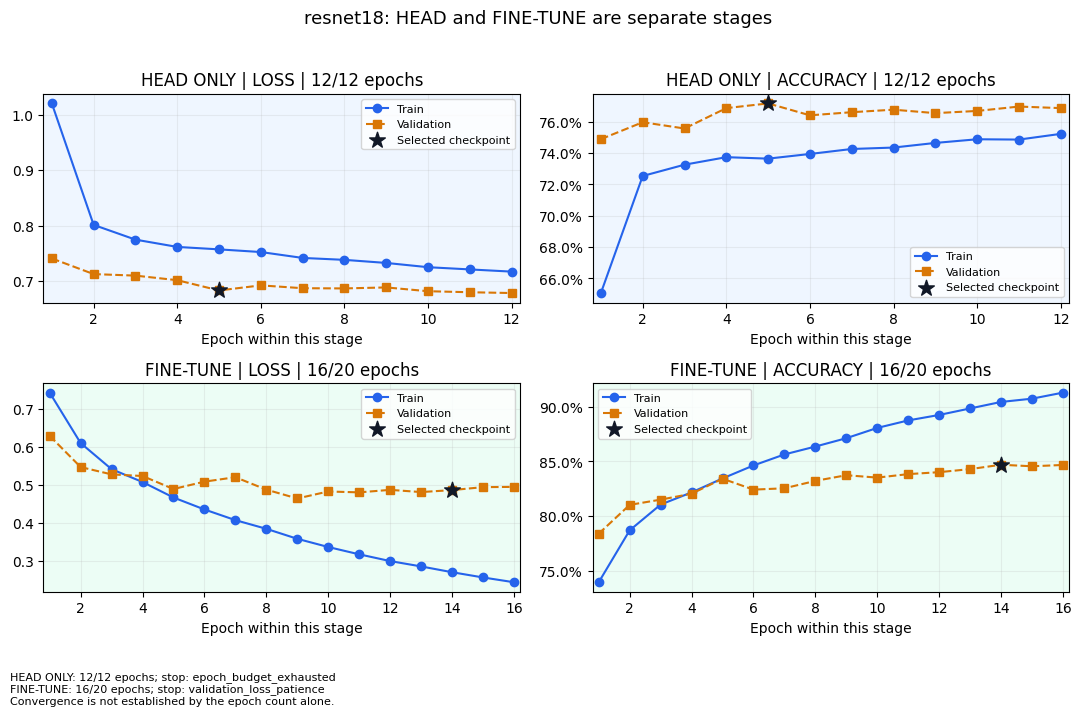

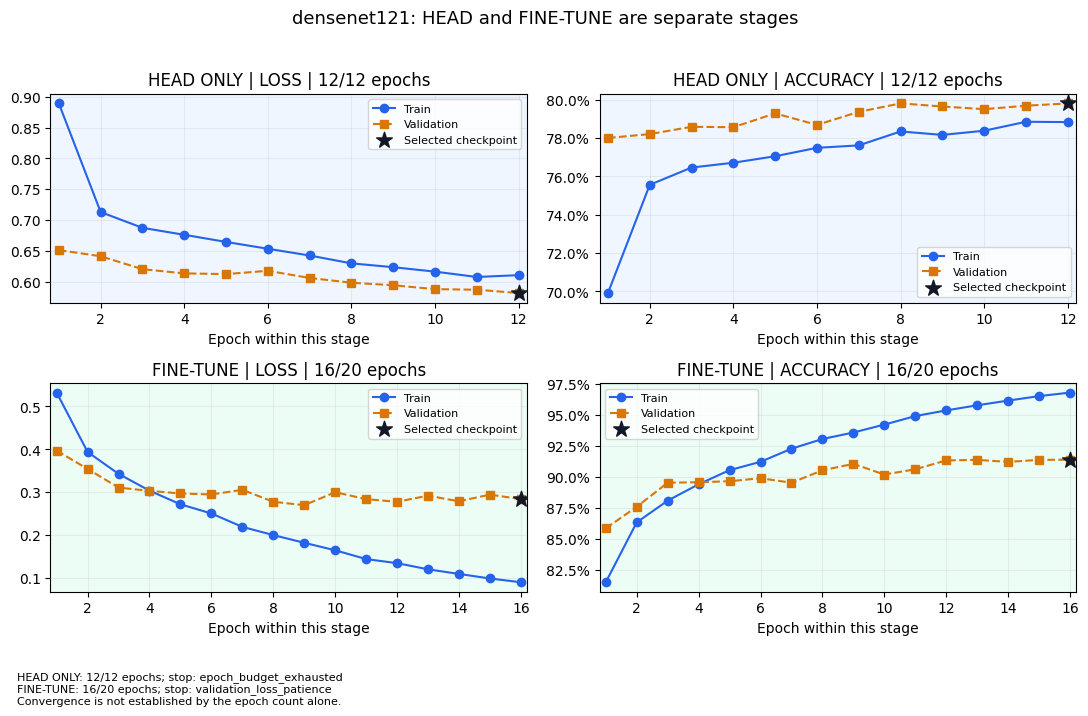

In [4]:
view.epoch_budget(RUN, ROOT)
view.learning_curves(RUN, OUT)

## 4. Kết quả TEST

Accuracy, macro precision/recall/F1 càng cao càng tốt; loss càng thấp càng tốt. Macro F1 là trung bình F1 từng lớp. Không dùng test chọn cấu hình.

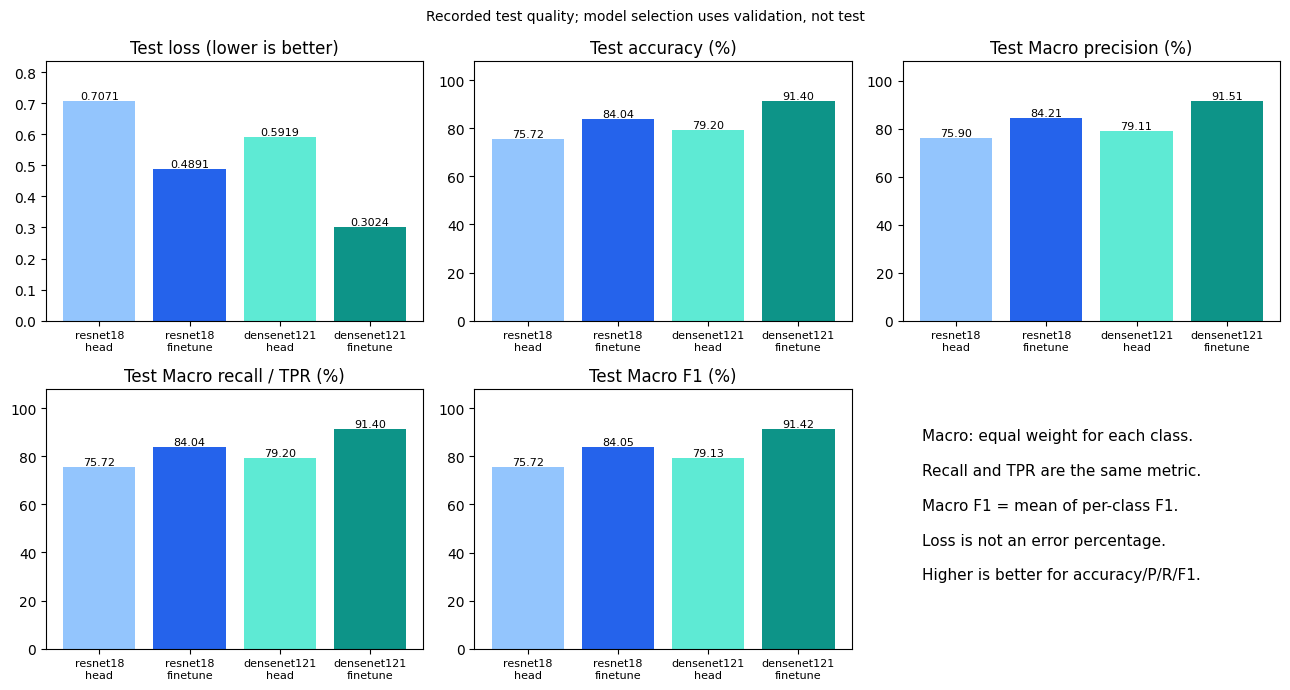

,model,stage,loss,accuracy (%),macro_precision (%),macro_recall (%),macro_f1 (%),execution
0,resnet18,head,0.7071,75.72,75.9035,75.72,75.7175,pooled_feature_cache
1,resnet18,finetune,0.4891,84.04,84.2119,84.04,84.0480,full_image_forward
2,densenet121,head,0.5919,79.20,79.1117,79.20,79.1268,pooled_feature_cache
3,densenet121,finetune,0.3024,91.40,91.5147,91.40,91.4195,full_image_forward


In [5]:
view.quality_cost(RUN, OUT)

## 5. Phân tích lỗi TEST — fine-tune

P/R/F1 cao tốt; FPR thấp tốt. Bảng ngắn lấy 2 lớp F1 thấp nhất/model; số trong bảng là tỷ lệ 0–1, heatmap dùng %. Confusion matrix: hàng thật, cột dự đoán. Lưới ảnh minh họa không đại diện accuracy.

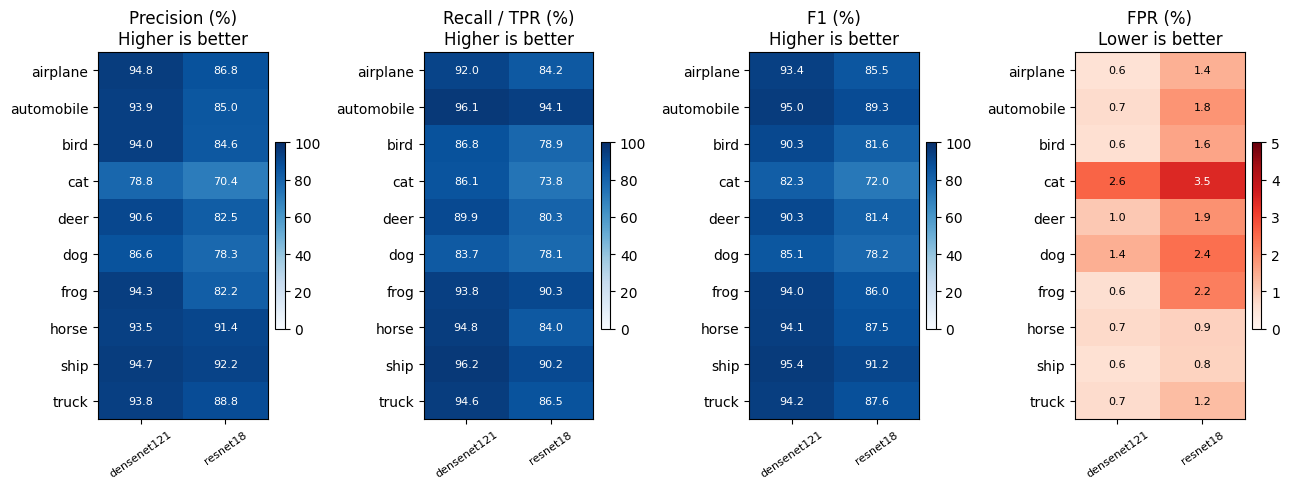

,model,stage,class,precision,recall_tpr,f1,fpr
13,resnet18,finetune,cat,0.7035,0.738,0.7204,0.0346
15,resnet18,finetune,dog,0.7826,0.781,0.7818,0.0241
33,densenet121,finetune,cat,0.7885,0.861,0.8231,0.0257
35,densenet121,finetune,dog,0.8665,0.837,0.8515,0.0143


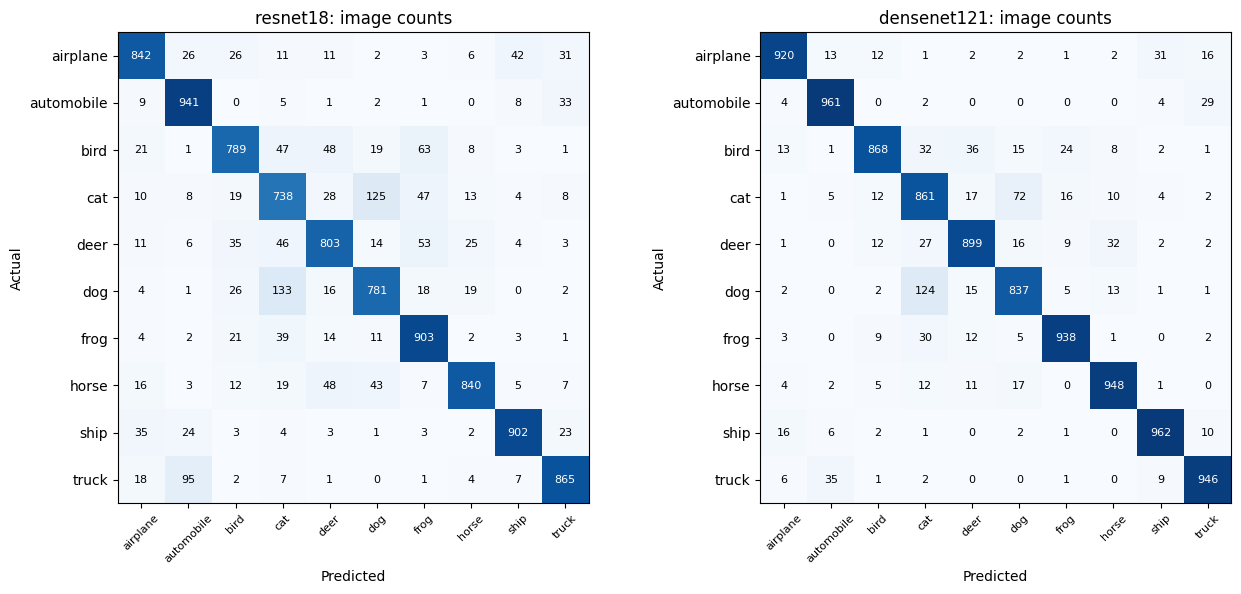

,model,actual,predicted,count,within_actual_class_pct
0,resnet18,dog,cat,133,13.3
1,resnet18,cat,dog,125,12.5
2,resnet18,truck,automobile,95,9.5
3,densenet121,dog,cat,124,12.4
4,densenet121,cat,dog,72,7.2
5,densenet121,bird,deer,36,3.6


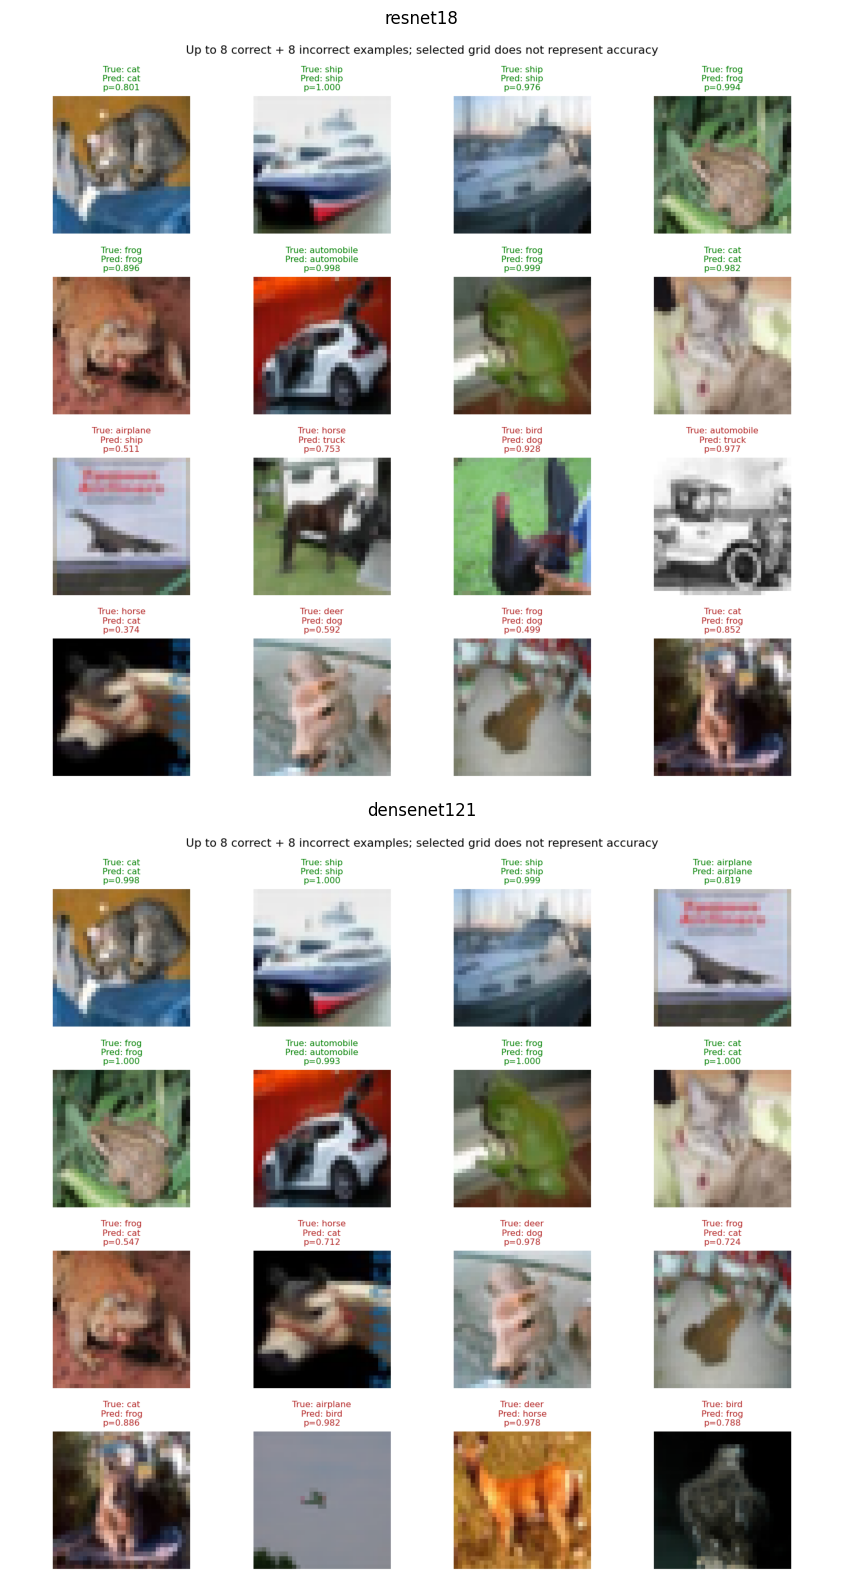

In [6]:
view.errors(RUN, OUT)
view.evidence(RUN, "confusion_matrix")
view.evidence(RUN, "prediction_examples")

## 6. ROC / PR — TEST

One-vs-rest qua nhiều ngưỡng. ROC AUC và PR không phải accuracy; khác metric argmax.

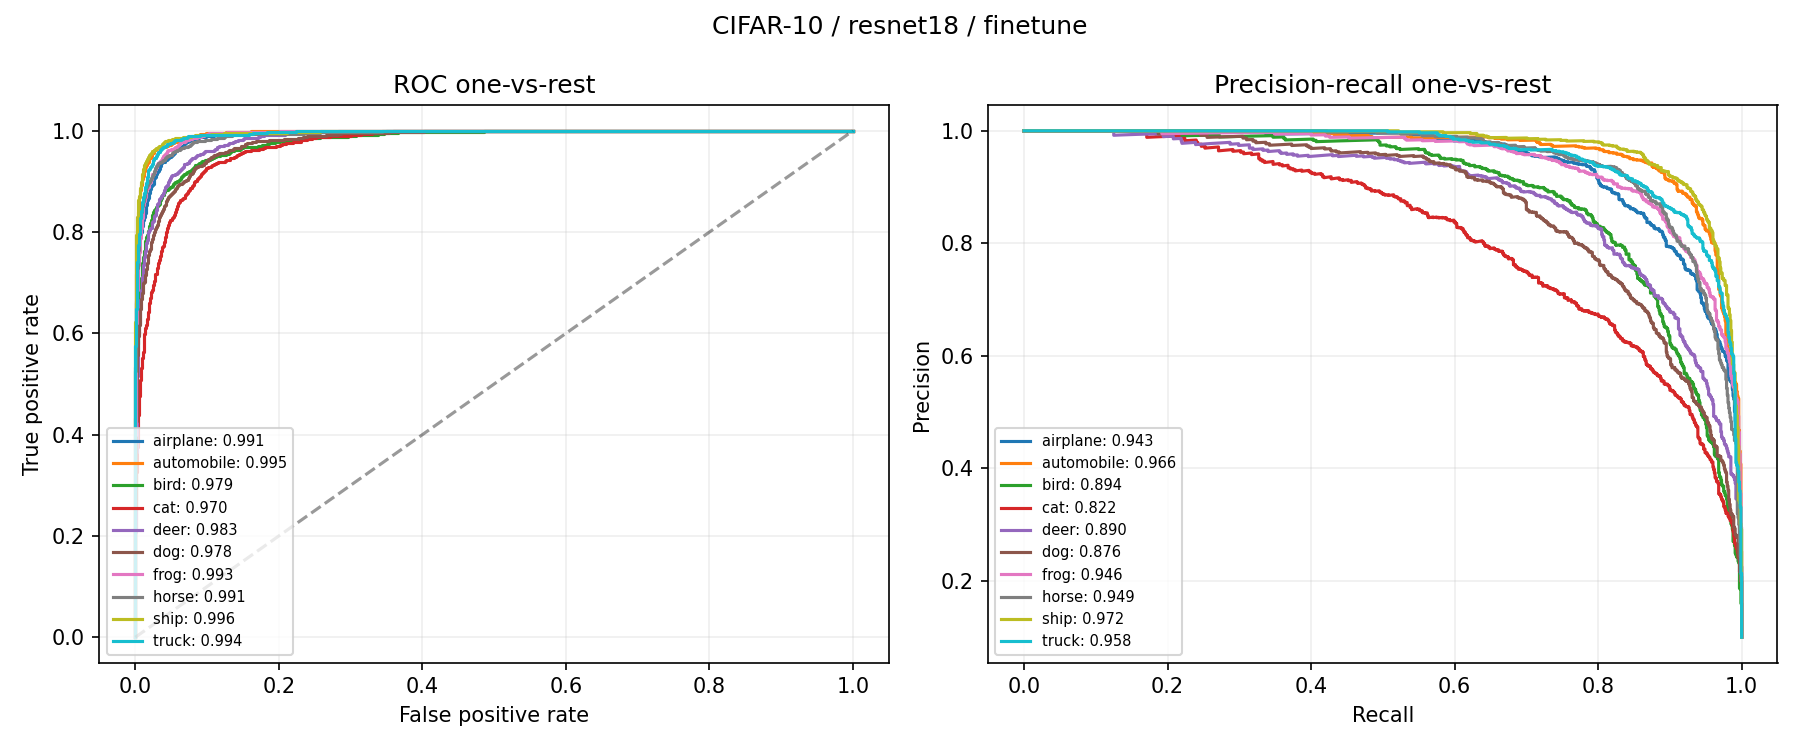

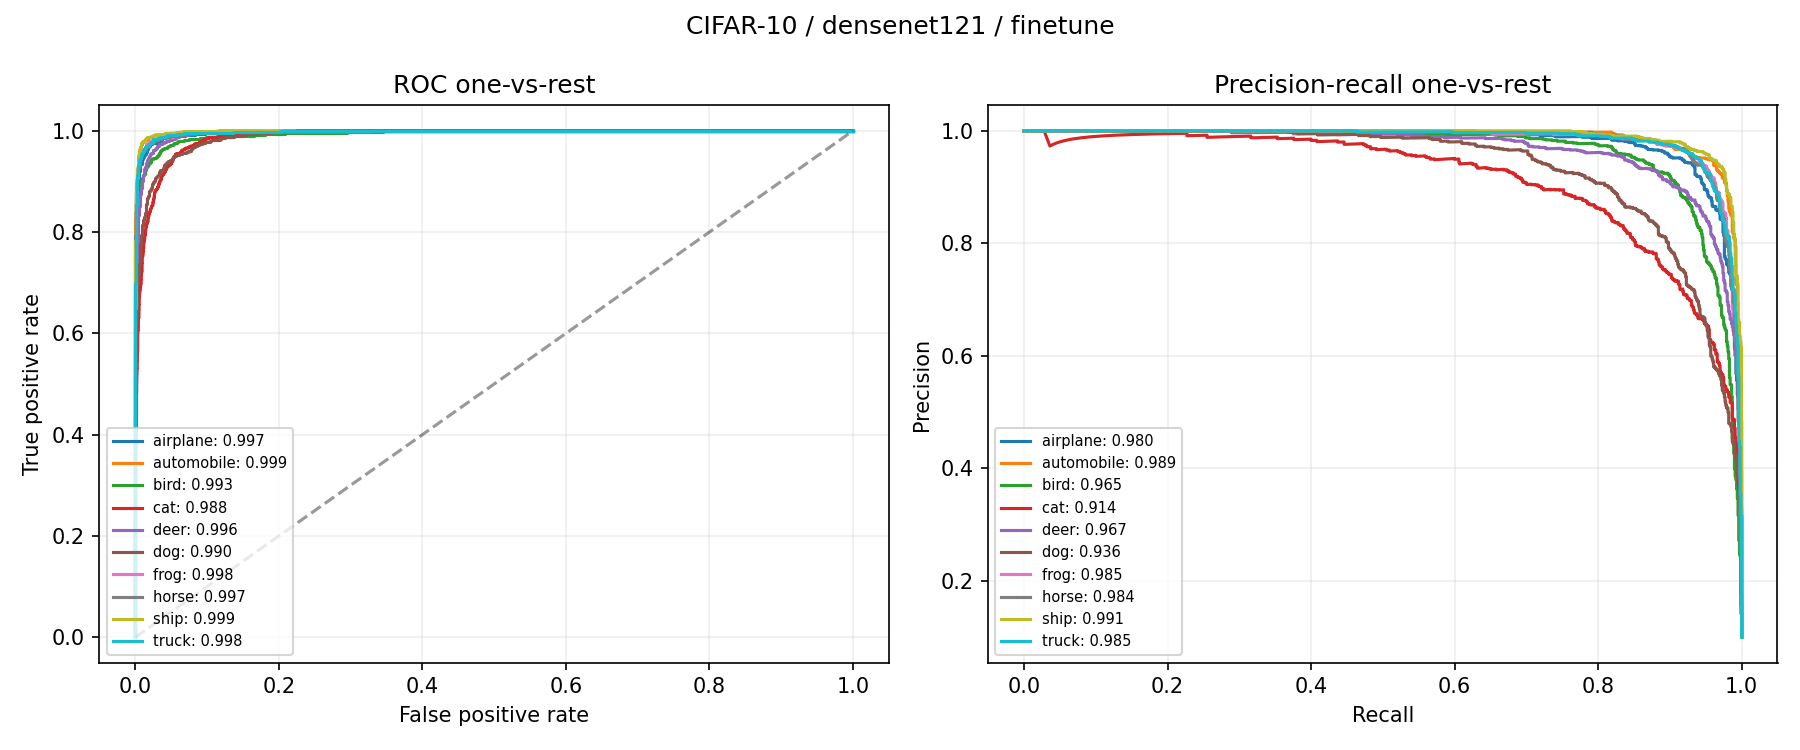

,model,classes,Macro ROC AUC (OvR),Macro average precision (OvR)
0,resnet18,10,0.9871,0.9215
1,densenet121,10,0.9954,0.9698


In [7]:
view.roc_pr(RUN)

## 7. Chi phí và artifact

Mở xen kẽ DenseNet vẫn cần backward về block3 layer11. Tỷ lệ tham số không trực tiếp quyết định chi phí. Kết quả chỉ đại diện seed/run này; chưa cô lập riêng tác động freeze và scheduler.

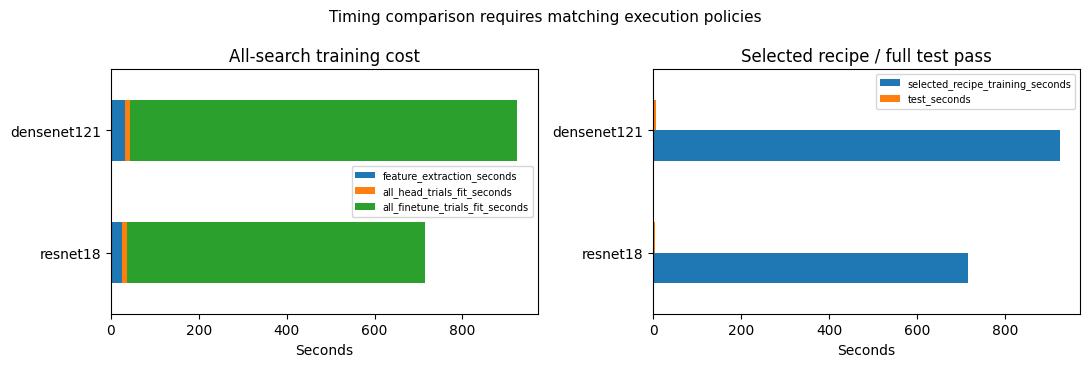

,model,execution,pipeline_training_seconds,selected_recipe_training_seconds,test_seconds
1,resnet18,full_image_forward,715.20,715.20,4.59
3,densenet121,full_image_forward,924.54,924.54,6.23


,model,val_accuracy,val_loss,time_comparable
0,densenet121,0.9138,0.283521,True


,run,event_files,best_checkpoints,live_server,historical_server_record
0,20261030T092411Z_cifar10_scheduled64_6f6f0f4b,10,6,not probed,False


In [8]:
view.efficiency(RUN, OUT)
view.monitoring_status(RUN)